In [1]:
import pickle
import pathlib

import numpy as np
import pandas as pd
import matplotlib as mlp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from models.EEGNet import EEGNet, ConstrainedConv2d, ConstrainedLinear
from models.GATGRU import MultiBranchGATGRUTransformer, SpatialBranch, FrequencyBranch, TemporalBranch, GATLayer

RESULTS_DIR = pathlib.Path('out/results')

def load_cached(name: str):
    cache_path = RESULTS_DIR / f"{name}.pkl"

    with open(cache_path, "rb") as fh:
        cached = pickle.load(fh)
        return cached["result"]

rf_general_run, rf_general_run_meta = load_cached('rf_general_run')
rf_cross_session_run, rf_cross_session_run_meta = load_cached('rf_cross_session_run')
rf_leave_one_out_run = load_cached('rf_leave_one_out_run')
rf_leave_one_out_gaze_run = load_cached('rf_leave_one_out_gaze_run')
rf_leave_one_out_hinted_run = load_cached('rf_leave_one_out_hinted_run')
rf_leave_one_out_finger_run = load_cached('rf_leave_one_out_finger_run')
rf_leave_one_out_augmented_run = load_cached('rf_leave_one_out_augmented_run')
rf_robust_general_run, rf_robust_general_run_meta = load_cached('rf_robust_general_run')
rf_robust_leave_one_out_run = load_cached('rf_robust_leave_one_out_run')

eegnet_general_run, eegnet_general_run_meta = load_cached('eegnet_general_run')
eegnet_cross_session_run, eegnet_cross_session_run_meta = load_cached('eegnet_cross_session_run')
eegnet_leave_one_out_run = load_cached('eegnet_leave_one_out_run')
eegnet_leave_one_out_gaze_run = load_cached('eegnet_leave_one_out_gaze_run')
eegnet_leave_one_out_hinted_run = load_cached('eegnet_leave_one_out_hinted_run')
eegnet_leave_one_out_ignored_run = load_cached('eegnet_leave_one_out_ignored_run')
eegnet_leave_one_out_augmented_run = load_cached('eegnet_leave_one_out_augmented_run')
eegnet_leave_one_out_finger_run = load_cached('eegnet_leave_one_out_finger_run')
eegnet_robust_general_run, eegnet_robust_general_run_meta = load_cached('eegnet_robust_general_run')
eegnet_robust_leave_one_out_run = load_cached('eegnet_robust_leave_one_out_run')

transformer_general_run = load_cached('transformer_general_run')
transformer_cross_session_run, transformer_cross_session_run_meta = load_cached('transformer_cross_session_run')
transformer_leave_one_out_run = load_cached('transformer_leave_one_out_run')
transformer_leave_one_out_gaze_run = load_cached('transformer_leave_one_out_gaze_run')
transformer_leave_one_out_hinted_run = load_cached('transformer_leave_one_out_hinted_run')
transformer_leave_one_out_ignored_run = load_cached('transformer_leave_one_out_ignored_run')
transformer_leave_one_out_augmented_run = load_cached('transformer_leave_one_out_augmented_run')
transformer_leave_one_out_finger_run = load_cached('transformer_leave_one_out_finger_run')
transformer_robust_general_run = load_cached('transformer_robust_general_run')
transformer_robust_leave_one_out_run = load_cached('transformer_robust_leave_one_out_run')

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


# Results analysis

In [2]:
from scripts.paper_style import (TEXT_W, COL_W, CAT_COLORS, SEQ_CMAP, DIV_CMAP, INK_PRIMARY, INK_SECONDARY,
                         GRID_COLOR, SPINE_COLOR, clean_axes, enforce_font_sizes, subject_id)

OUT_DIR = pathlib.Path('out/figs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    enforce_font_sizes(fig)
    path = OUT_DIR / name
    fig.savefig(path)
    print('wrote', path)

wrote out\figs\model_perf_by_dataset_split.pdf


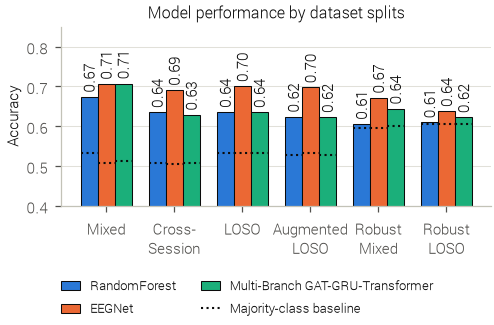

In [11]:
# model comparison - overall
def majority_baseline(result):
    """Accuracy of a constant classifier predicting the test set's majority class (confusion-matrix rows = true labels)."""
    cm = np.asarray(result['confusion_matrix'])
    return cm.sum(axis=1).max() / cm.sum()

def run_scores(run):
    """(accuracy, majority baseline) of a single run, or the fold averages of a LOSO run."""
    if 'test_accuracy' in run:
        return run['test_accuracy'], majority_baseline(run)
    return (np.average([v['result']['test_accuracy'] for v in run.values()]),
            np.average([majority_baseline(v['result']) for v in run.values()]))

def plot_overall_performance_comparison():
    dataset_names = ['Mixed', 'Cross-\nSession', 'LOSO', 'Augmented\nLOSO', 'Robust\nMixed', 'Robust\nLOSO']
    runs = {
        'RandomForest': (rf_general_run, rf_cross_session_run, rf_leave_one_out_run,
                         rf_leave_one_out_augmented_run, rf_robust_general_run, rf_robust_leave_one_out_run),
        'EEGNet': (eegnet_general_run, eegnet_cross_session_run, eegnet_leave_one_out_run,
                   eegnet_leave_one_out_augmented_run, eegnet_robust_general_run, eegnet_robust_leave_one_out_run),
        'Multi-Branch GAT-GRU-Transformer': (transformer_general_run, transformer_cross_session_run, transformer_leave_one_out_run,
                                             transformer_leave_one_out_augmented_run, transformer_robust_general_run, transformer_robust_leave_one_out_run),
    }
    scores = {model: [run_scores(r) for r in model_runs] for model, model_runs in runs.items()}
    content = {model: tuple(acc for acc, _ in s) for model, s in scores.items()}
    baselines = {model: [base for _, base in s] for model, s in scores.items()}

    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 2.2))

    res = ax.grouped_bar(content, tick_labels=dataset_names, group_spacing=1, edgecolor=INK_PRIMARY, colors=CAT_COLORS[0:3])
    for container, model in zip(res.bar_containers, content):
        ax.bar_label(container, padding=2, fmt="%.2f", rotation=90)  # vertical: 18 bars share one column
        # majority-class baseline of each bar's own test set, drawn across the bar
        for bar, base in zip(container.patches, baselines[model]):
            ax.hlines(base, bar.get_x(), bar.get_x() + bar.get_width(), colors=INK_PRIMARY, linestyles=':', linewidth=1)
    ax.plot([], [], color=INK_PRIMARY, linestyle=':', linewidth=1, label='Majority-class baseline')

    # Add some text for labels, title, etc.
    ax.set_ylabel('Accuracy')
    ax.set_title('Model performance by dataset splits')
    handles, labels = ax.get_legend_handles_labels()  # baseline line comes first; list it after the models
    fig.legend(handles[1:] + handles[:1], labels[1:] + labels[:1], frameon=False, loc='outside lower center', ncols=2)
    ax.set_ylim(0.4, 0.85)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    clean_axes(ax)
    savefig(fig, 'model_perf_by_dataset_split.pdf')

plot_overall_performance_comparison()

wrote out\figs\model_perf_by_distractors.pdf


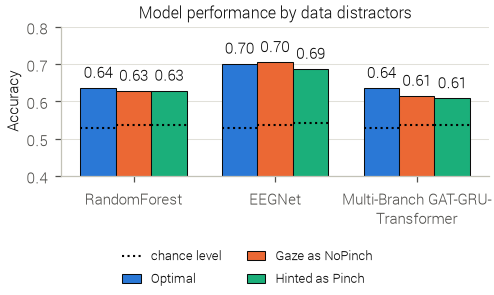

In [4]:
# model comparison - impact of hinted, ignored, and gaze events in leave-one-out

def get_accs_by_type(type: str):
    return (
        get_acc(globals()[f'rf_{type}']),
        get_acc(globals()[f'eegnet_{type}']),
        get_acc(globals()[f'transformer_{type}'])
    )

def get_baseline_by_type(type: str):
    return (
        get_baseline(globals()[f'rf_{type}']),
        get_baseline(globals()[f'eegnet_{type}']),
        get_baseline(globals()[f'transformer_{type}'])
    )

def get_acc(data: dict):
    if 'result' in data:
        return data['result']['test_accuracy']
    else:
        return np.average([v['result']['test_accuracy'] for k, v in data.items()])

def get_baseline(data: dict):
    """
    Estimate the baseline accuracy using the majority-class baseline.
    """
    if 'result' in data:
        cm = np.asarray(data['result']["confusion_matrix"])
        true_class_counts = cm.sum(axis=1)  # rows = true labels
        total = true_class_counts.sum()
        return true_class_counts.max() / total
    else:
        true_class_counts = 0
        total = 0
        for s in data.keys():
            cm = np.asarray(data[s]['result']["confusion_matrix"])
            true_class_counts += cm.sum(axis=1).max()  # rows = true labels
            total += cm.sum(axis=1).sum()

        return true_class_counts / total


def plot_overall_performance_comparison():
    dataset_names = ['RandomForest', 'EEGNet', 'Multi-Branch GAT-GRU-\nTransformer']
    content = {
        'Optimal': get_accs_by_type('leave_one_out_run'),
        'Gaze as NoPinch': get_accs_by_type('leave_one_out_gaze_run'),
        # 'Ignored as Pinch': get_accs_by_type('leave_one_out_ignored_run'),
        'Hinted as Pinch': get_accs_by_type('leave_one_out_hinted_run'),
        # 'Random finger movements\nas NoPinch': get_accs_by_type('leave_one_out_run'),
    }
    chance = {
        'Optimal': get_baseline_by_type('leave_one_out_run'),
        'Gaze as NoPinch': get_baseline_by_type('leave_one_out_gaze_run'),
        # 'Ignored as Pinch': get_baseline_by_type('leave_one_out_ignored_run'),
        'Hinted as Pinch': get_baseline_by_type('leave_one_out_hinted_run'),
        # 'Random finger movements\nas NoPinch': (0.5, 0.5, 0.5),
    }

    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 2))

    res = ax.grouped_bar(content, tick_labels=dataset_names, group_spacing=1, edgecolor=INK_PRIMARY, colors=CAT_COLORS[0:3])

    # plot a per-bar chance level (determined by the ratio of the dominant class)
    first_line = True
    for label, container in zip(content, res.bar_containers):
        for bar, c in zip(container.patches, chance[label]):
            ax.hlines(c, bar.get_x(), bar.get_x() + bar.get_width(),
                      colors='black', linestyles=':', linewidth=1.0,
                      label='chance level' if first_line else None)
            first_line = False

    for container in res.bar_containers:
        ax.bar_label(container, padding=3, fmt="%.2f")

    ax.set_ylabel('Accuracy')
    ax.set_title('Model performance by data distractors')
    fig.legend(frameon=False, loc='outside lower center', ncols=2)
    ax.set_ylim(0.4, 0.8)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    clean_axes(ax)
    savefig(fig, 'model_perf_by_distractors.pdf')

    # Add some text for labels, title, etc.

plot_overall_performance_comparison()

In [5]:
# model comparison - impact of feedback

[0.6479750871658325, 0.7039473652839661, 0.7372262477874756, 0.6655405163764954, 0.6785714030265808, 0.6393939256668091, 0.6205357313156128, 0.7542662024497986, 0.7453183531761169, 0.6461039185523987, 0.8119403123855591, 0.6911764740943909, 0.6206896305084229, 0.6483516693115234, 0.7555555701255798, 0.7399463653564453, 0.8038673996925354, 0.6577380895614624, 0.738095223903656]
wrote out\figs\subject_comparison.pdf


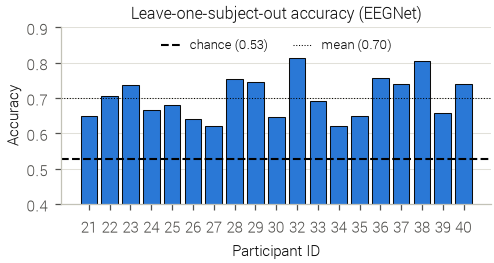

In [6]:
# showing the differences between subjects
def plot_subject_comparison():
    results = eegnet_leave_one_out_run
    accuracies = [result['result']['test_accuracy'] for result in results.values()]
    print(accuracies)
    chance = get_baseline_by_type('leave_one_out_run')
    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 1.8))
    ax.bar([subject_id(s) for s in results], accuracies, edgecolor=INK_PRIMARY, color=CAT_COLORS[0])
    ax.set_xlabel("Participant ID")
    ax.set_ylabel("Accuracy")
    ax.set_title("Leave-one-subject-out accuracy (EEGNet)")
    ax.set_ylim(0.4, 0.9)
    ax.axhline(chance[1], color="black", linestyle="--", linewidth=1.0,
        label=f"chance ({chance[1]:.2f})",
    )
    ax.axhline(np.mean(accuracies), color="black", linestyle=":", linewidth=0.5,
        label=f"mean ({np.mean(accuracies):.2f})",
    )
    ax.legend(frameon=False, loc='upper center', ncols=2)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    clean_axes(plt.gca())
    savefig(fig, 'subject_comparison.pdf')


plot_subject_comparison()

## Reporting all results currently available

In [7]:
import os


def compute_metrics(data):
    cm = np.array(data["confusion_matrix"], dtype=float)
    classes = list(data["classes"])
    pos_idx = classes.index('PinchLog')

    total = cm.sum()
    correct = np.trace(cm)
    accuracy = correct / total

    tp = cm[pos_idx, pos_idx]
    fp = cm[:, pos_idx].sum() - tp
    fn = cm[pos_idx, :].sum() - tp
    tn = total - tp - fp - fn

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "fpr": fpr,
    }


def mean_of_dicts(dict_list):
    keys = dict_list[0].keys()
    return {
        key: np.mean([d[key] for d in dict_list])
        for key in keys
    }

def report_results(folder_path):
    results = {}
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        if os.path.isfile(file_path) and filename.endswith('_run.pkl'):  # skip non-result caches such as rf_feature_store.pkl
            name_without_ext = os.path.splitext(filename)[0]
            data = load_cached(name_without_ext)
            # prepare data layout
            if isinstance(data, tuple):
                data = {
                    'result': data[0],
                    'test_metadata': data[1],
                }
            if 'model' in data:
                data = {
                    'result': data
                }
            # compute results
            if 'result' in data:
                results[name_without_ext] = compute_metrics(data['result'])
                pass
            else:
                # compute mean
                vals = []
                for s in data.keys():
                    vals.append(compute_metrics(data[s]['result']))

                results[name_without_ext] = mean_of_dicts(vals)

    df = pd.DataFrame.from_dict(results).T
    print_latex_table_body(df)
    return df


# rows of tab:resultsModels: (run-name infix, dataset label lines); the label is centred on the
# EEGNet row, a two-line label starts on the RF row
TABLE_DATASETS = [
    ('general_run', ['Mixed']),
    ('leave_one_out_run', ['LOSO']),
    ('cross_session_run', ['Cross-Session']),
    ('leave_one_out_augmented_run', ['LOSO', 'Augmented']),
    ('robust_general_run', ['Robust', 'Mixed']),
    ('robust_leave_one_out_run', ['Robust', 'LOSO']),
]
TABLE_MODELS = [('RF', 'rf'), ('EEGNet', 'eegnet'), ('Transformer', 'transformer')]
TABLE_METRICS = ['accuracy', 'precision', 'recall', 'f1', 'fpr']


def print_latex_table_body(df):
    """Prints the rows between \\midrule and \\bottomrule of tab:resultsModels (metrics in %, LOSO = fold mean)."""
    label_w = max(len(l) for _, labels in TABLE_DATASETS for l in labels)
    model_w = max(len(m) for m, _ in TABLE_MODELS)
    blocks = []
    for infix, labels in TABLE_DATASETS:
        cells = [''] * len(TABLE_MODELS)
        start = 0 if len(labels) > 1 else 1
        cells[start:start + len(labels)] = labels
        rows = []
        for (model, prefix), label in zip(TABLE_MODELS, cells):
            vals = df.loc[f'{prefix}_{infix}', TABLE_METRICS]
            rows.append(f'    {model:<{model_w}} & {label:<{label_w}} & '
                        + ' & '.join(f'{100 * v:4.1f}' for v in vals) + r' \\')
        blocks.append('\n'.join(rows))
    print('\n    \\hline\n'.join(blocks))


results = report_results('out/results')

    RF          &               & 67.4 & 64.2 & 68.5 & 66.3 & 33.6 \\
    EEGNet      & Mixed         & 70.6 & 70.8 & 71.8 & 71.3 & 30.6 \\
    Transformer &               & 70.7 & 69.1 & 72.4 & 70.7 & 30.9 \\
    \hline
    RF          &               & 63.5 & 65.6 & 58.7 & 60.8 & 31.2 \\
    EEGNet      & LOSO          & 70.0 & 71.5 & 67.5 & 68.5 & 27.1 \\
    Transformer &               & 63.5 & 64.5 & 68.0 & 63.7 & 40.2 \\
    \hline
    RF          &               & 63.5 & 65.2 & 55.3 & 59.8 & 28.5 \\
    EEGNet      & Cross-Session & 69.1 & 69.3 & 67.5 & 68.4 & 29.3 \\
    Transformer &               & 62.9 & 63.3 & 58.4 & 60.7 & 32.8 \\
    \hline
    RF          & LOSO          & 62.4 & 63.2 & 58.8 & 59.6 & 33.6 \\
    EEGNet      & Augmented     & 69.7 & 70.6 & 70.7 & 69.5 & 30.4 \\
    Transformer &               & 62.3 & 63.7 & 66.5 & 61.3 & 41.4 \\
    \hline
    RF          & Robust        & 60.6 & 66.7 &  4.7 &  8.8 &  1.6 \\
    EEGNet      & Mixed         & 67.1 & 59.8 

In [8]:
results

,accuracy,precision,recall,f1,fpr
eegnet_cross_session_run,0.691011,0.693005,0.674653,0.683706,0.292954
eegnet_general_run,0.706320,0.707581,0.717949,0.712727,0.305660
eegnet_leave_one_out_augmented_run,0.697317,0.705967,0.706527,0.694560,0.303824
eegnet_leave_one_out_finger_run,0.699985,0.729780,0.678224,0.688749,0.275771
eegnet_leave_one_out_gaze_run,0.704524,0.704242,0.695111,0.690625,0.280862
eegnet_leave_one_out_hinted_run,0.686485,0.739310,0.696218,0.702299,0.315942
eegnet_leave_one_out_ignored_run,0.684573,0.731184,0.659414,0.675307,0.275791
eegnet_leave_one_out_run,0.700328,0.715104,0.674900,0.685284,0.271488
eegnet_light_general_run,0.732609,0.724036,0.727273,0.725651,0.262341
eegnet_robust_cross_session_run,0.647515,0.581431,0.434091,0.497072,0.209444


In [9]:
# LOSO mean accuracy under relabelling/augmentation variants (thesis table tab:robustness)
# runs are loaded by file name, one at a time (the RF pickles are large); mean = average per-fold test accuracy,
# std = fold-to-fold population std (ddof=0, as in model_metrics_loso.csv)
from scipy.stats import wilcoxon

LOSO_VARIANTS = {
    'Base LOSO': '',
    'Gaze $\\to$ negative': '_gaze',
    'Finger movement $\\to$ negative': '_finger',
    'Hinted $\\to$ positive': '_hinted',
    'Ignored $\\to$ positive': '_ignored',
    'Augmented': '_augmented',
}
LOSO_MODELS = {'RF': 'rf', 'EEGNet': 'eegnet', 'Transf.': 'transformer'}

fold_acc = {}  # (variant, model) -> per-fold accuracy, indexed by held-out subject
for variant, suffix in LOSO_VARIANTS.items():
    for model, prefix in LOSO_MODELS.items():
        run = load_cached(f'{prefix}_leave_one_out{suffix}_run')
        fold_acc[variant, model] = pd.Series({s: v['result']['test_accuracy'] for s, v in run.items()})
        del run

robustness_df = pd.DataFrame({m: [fold_acc[v, m].mean() for v in LOSO_VARIANTS] for m in LOSO_MODELS},
                             index=list(LOSO_VARIANTS))
robustness_std_df = pd.DataFrame({m: [fold_acc[v, m].std(ddof=0) for v in LOSO_VARIANTS] for m in LOSO_MODELS},
                                 index=list(LOSO_VARIANTS))
base_std = robustness_std_df.loc['Base LOSO']
max_dev = (robustness_df - robustness_df.loc['Base LOSO']).abs().max()
print('folds per run:', sorted({len(a) for a in fold_acc.values()}))
print('base fold-to-fold std:', {m: round(float(s), 3) for m, s in base_std.items()})
print('largest |variant - base|:', {m: round(float(d), 3) for m, d in max_dev.items()})
print('\naccuracy in %, mean $\\pm$ fold-to-fold std:')
for variant, row in robustness_df.iterrows():
    stds = robustness_std_df.loc[variant]
    print(f'    {variant:<30}& ' + ' & '.join(f'{100 * x:.1f} $\\pm$ {100 * sd:.1f}' for x, sd in zip(row, stds)) + r' \\')

# each variant vs. the same model's base run: paired Wilcoxon signed-rank test over the held-out subjects,
# Bonferroni-corrected for all variant x model comparisons in the table
sig_rows = []
for variant in list(LOSO_VARIANTS)[1:]:
    for model in LOSO_MODELS:
        base, var = fold_acc['Base LOSO', model], fold_acc[variant, model]
        assert set(base.index) == set(var.index), f'{variant}/{model}: different held-out subjects than base'
        diff = var[base.index] - base
        stat, p = (float('nan'), 1.0) if np.allclose(diff, 0) else wilcoxon(var[base.index], base)
        sig_rows.append(dict(variant=variant, model=model, mean_diff=diff.mean(), n_better=int((diff > 0).sum()),
                             n_worse=int((diff < 0).sum()), wilcoxon_W=stat, p_value=p))
robustness_sig_df = pd.DataFrame(sig_rows)
robustness_sig_df['p_bonferroni'] = (robustness_sig_df['p_value'] * len(robustness_sig_df)).clip(upper=1.0)
print(f'\nvariant vs. base, paired Wilcoxon over {len(base)} held-out subjects, '
      f'Bonferroni-corrected for {len(robustness_sig_df)} comparisons:')
print(robustness_sig_df.round(4).to_string(index=False))
robustness_df.map('{:.3f}'.format) + ' ± ' + robustness_std_df.map('{:.3f}'.format)

folds per run: [19]
base fold-to-fold std: {'RF': 0.052, 'EEGNet': 0.058, 'Transf.': 0.065}
largest |variant - base|: {'RF': 0.012, 'EEGNet': 0.016, 'Transf.': 0.027}

accuracy in %, mean $\pm$ fold-to-fold std:
    Base LOSO                     & 63.5 $\pm$ 5.2 & 70.0 $\pm$ 5.8 & 63.5 $\pm$ 6.5 \\
    Gaze $\to$ negative           & 62.7 $\pm$ 5.5 & 70.5 $\pm$ 5.1 & 61.4 $\pm$ 5.3 \\
    Finger movement $\to$ negative& 63.4 $\pm$ 4.8 & 70.0 $\pm$ 5.2 & 62.3 $\pm$ 5.3 \\
    Hinted $\to$ positive         & 62.8 $\pm$ 5.1 & 68.6 $\pm$ 6.3 & 60.8 $\pm$ 5.1 \\
    Ignored $\to$ positive        & 63.2 $\pm$ 4.6 & 68.5 $\pm$ 6.2 & 61.9 $\pm$ 5.8 \\
    Augmented                     & 62.4 $\pm$ 4.9 & 69.7 $\pm$ 5.9 & 62.3 $\pm$ 6.4 \\

variant vs. base, paired Wilcoxon over 19 held-out subjects, Bonferroni-corrected for 15 comparisons:
                       variant   model  mean_diff  n_better  n_worse  wilcoxon_W  p_value  p_bonferroni
           Gaze $\to$ negative      RF    -0.0080    

,RF,EEGNet,Transf.
Base LOSO,0.635 ± 0.052,0.700 ± 0.058,0.635 ± 0.065
Gaze $\to$ negative,0.627 ± 0.055,0.705 ± 0.051,0.614 ± 0.053
Finger movement $\to$ negative,0.634 ± 0.048,0.700 ± 0.052,0.623 ± 0.053
Hinted $\to$ positive,0.628 ± 0.051,0.686 ± 0.063,0.608 ± 0.051
Ignored $\to$ positive,0.632 ± 0.046,0.685 ± 0.062,0.619 ± 0.058
Augmented,0.624 ± 0.049,0.697 ± 0.059,0.623 ± 0.064


findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXSizeOneSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeTwoSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeThreeSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFourSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight 300 for cmmi10, now using 400.
findfont: Failed to find font weight 300 for cmsy10, now using 400.
findfont: Failed to find font weight 300 for cmr10, now using 400.
findfont: Failed to find font weight 300 for cmtt10, now using 400.
findfont: Failed to find font weight 300 for cm

wrote out\figs\loso_robustness_variants.pdf


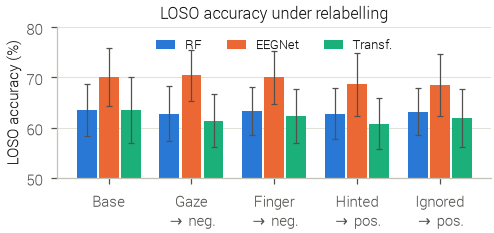

In [10]:
# one-column figure of the table above: LOSO accuracy (mean +- fold-to-fold std) per relabelling variant and model
# (the augmented run is only reported in the table)
VARIANT_TICKS = {
    'Base LOSO': 'Base',
    'Gaze $\\to$ negative': 'Gaze\n$\\to$ neg.',
    'Finger movement $\\to$ negative': 'Finger\n$\\to$ neg.',
    'Hinted $\\to$ positive': 'Hinted\n$\\to$ pos.',
    'Ignored $\\to$ positive': 'Ignored\n$\\to$ pos.',
}

def plot_loso_robustness():
    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 1.6))
    means = robustness_df.loc[list(VARIANT_TICKS)]
    stds = robustness_std_df.loc[list(VARIANT_TICKS)]
    x = np.arange(len(means))
    width = 0.8 / len(LOSO_MODELS)
    for i, model in enumerate(LOSO_MODELS):
        offset = (i - (len(LOSO_MODELS) - 1) / 2) * width
        ax.bar(x + offset, 100 * means[model], width * 0.9, color=CAT_COLORS[i], label=model,
               yerr=100 * stds[model], ecolor=INK_SECONDARY,
               error_kw=dict(elinewidth=0.6, capsize=1.5, capthick=0.6))
    ax.set_xticks(x)
    ax.set_xticklabels(list(VARIANT_TICKS.values()))
    ax.set_ylabel('LOSO accuracy (%)')
    ax.set_title('LOSO accuracy under relabelling')
    ax.set_ylim(50, 80)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc='upper center', ncols=len(LOSO_MODELS))
    clean_axes(ax)
    savefig(fig, 'loso_robustness_variants.pdf')


plot_loso_robustness()